# 99 — Comparison

This notebook does not implement a forecast. It reads every method that has been published for the active baseline:

```
outputs/baselines/<GPU_BASE_PLAN>/methods/<method_id>/
    meta.json
    predictions.csv
```

`predictions.csv` has `date`, `y_true`, and `y_pred`. `meta.json` has `method_id`, `stage`, `label`, and `description`.

To add a method, write those two files and run this notebook again. Methods already on disk stay in the comparison. Changing `GPU_BASE_PLAN` reads that baseline's own folder and leaves the others in place.


In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

from icx.forecast import error_table, load_published_methods
from icx.runtime import require_project_venv
from icx.store import open_store

ROOT = require_project_venv()
layout = open_store(ROOT)
print(f"Project:  {ROOT}")
print(f"Python:   {sys.executable}")
print(f"Baseline: {layout.baseline.key}")

published = load_published_methods(layout)
if not published:
    raise RuntimeError("No published methods. Run 05_nowcast.ipynb first, or add a methods/ folder.")
print(f"Methods: {len(published)}")
for meta, frame in published:
    print(f"  {meta['method_id']:22} {meta.get('label', '')}  rows={len(frame)}")


Project:  /home/neoabs/src/gka/ICX
Python:   /home/neoabs/src/gka/ICX/.venv/bin/python
Baseline: nvidia-h100__ON_DEMAND
Methods: 5
  03_fixed_price         Fixed-price index  rows=44
  03_moving_price        Moving-price index  rows=92
  04_cluster_basket      Cluster basket  rows=92
  05_carry_forward       Carry forward  rows=92
  05_ridge               Ridge on log prices  rows=91


In [2]:
summary = error_table(published)
print("Each method on the dates it could score")
print(summary.to_string(index=False))

common_dates = None
for _meta, frame in published:
    dates = set(frame["date"].astype(str))
    common_dates = dates if common_dates is None else common_dates & dates
common_published = []
for meta, frame in published:
    common_published.append((meta, frame.loc[frame["date"].astype(str).isin(common_dates)].copy()))
common_summary = error_table(common_published)
print()
print(f"Same {len(common_dates)} dates for every method")
print(common_summary.to_string(index=False))


Each method on the dates it could score
        method_id stage               label  n      mae     rmse     mape
 05_carry_forward    05       Carry forward 92 0.025218 0.050359 0.007972
         05_ridge    05 Ridge on log prices 91 0.074726 0.090408 0.023503
  03_moving_price    03  Moving-price index 92 0.183861 0.205271 0.057407
04_cluster_basket    04      Cluster basket 92 0.185020 0.216483 0.057539
   03_fixed_price    03   Fixed-price index 44 0.426392 0.531540 0.134241

Same 44 dates for every method
        method_id stage               label  n      mae     rmse     mape
 05_carry_forward    05       Carry forward 44 0.029556 0.056642 0.009368
         05_ridge    05 Ridge on log prices 44 0.067817 0.079108 0.021640
  03_moving_price    03  Moving-price index 44 0.152873 0.175842 0.048349
04_cluster_basket    04      Cluster basket 44 0.161752 0.191538 0.050860
   03_fixed_price    03   Fixed-price index 44 0.426392 0.531540 0.134241


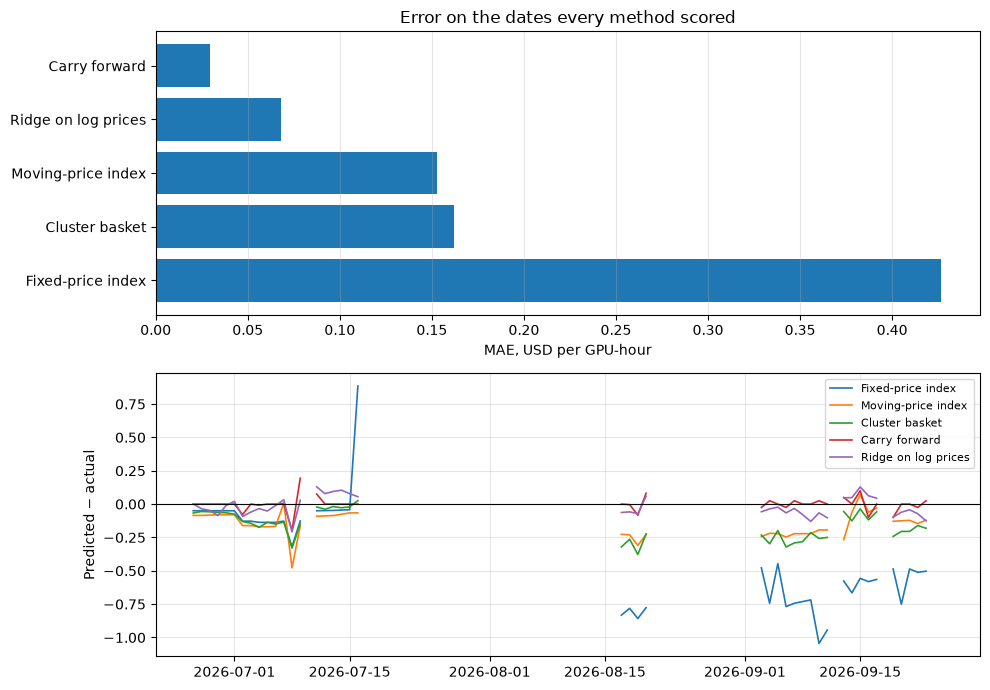

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
order = common_summary.sort_values("mae", ascending=False)
axes[0].barh(order["label"], order["mae"], color="tab:blue")
axes[0].set_xlabel("MAE, USD per GPU-hour")
axes[0].set_title("Error on the dates every method scored")
axes[0].grid(True, axis="x", alpha=0.3)


def plot_error(axis, frame, label):
    scored = frame.copy()
    scored["date"] = pd.to_datetime(scored["date"])
    scored["error"] = pd.to_numeric(scored["y_pred"]) - pd.to_numeric(scored["y_true"])
    scored = scored.dropna(subset=["error"]).sort_values("date")
    rows = []
    previous = None
    for row in scored.itertuples(index=False):
        if previous is not None and (row.date - previous).days > 1:
            rows.append({"date": previous + pd.Timedelta(days=1), "error": float("nan")})
        rows.append({"date": row.date, "error": row.error})
        previous = row.date
    line = pd.DataFrame(rows)
    axis.plot(line["date"], line["error"], label=label, lw=1.2)

for meta, frame in common_published:
    plot_error(axes[1], frame, meta.get("label", meta["method_id"]))
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylabel("Predicted − actual")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


## Reading the ranking

Carry-forward only repeats the last baseline price. It is strong here because H100 on-demand moves by a few cents a day. The fixed-price index is the calmest inverse index from stage 03, and because that price never changes the forecast cannot follow those moves. The moving-price index and the cluster basket use prices that do change; they are still less accurate than the last observed baseline price. Ridge, which is allowed to combine several contemporaneous prices, is the closest of the cross-sectional forecasts.

A new method belongs in this chart when its `predictions.csv` covers these dates. It does not need to be added to the list above.
